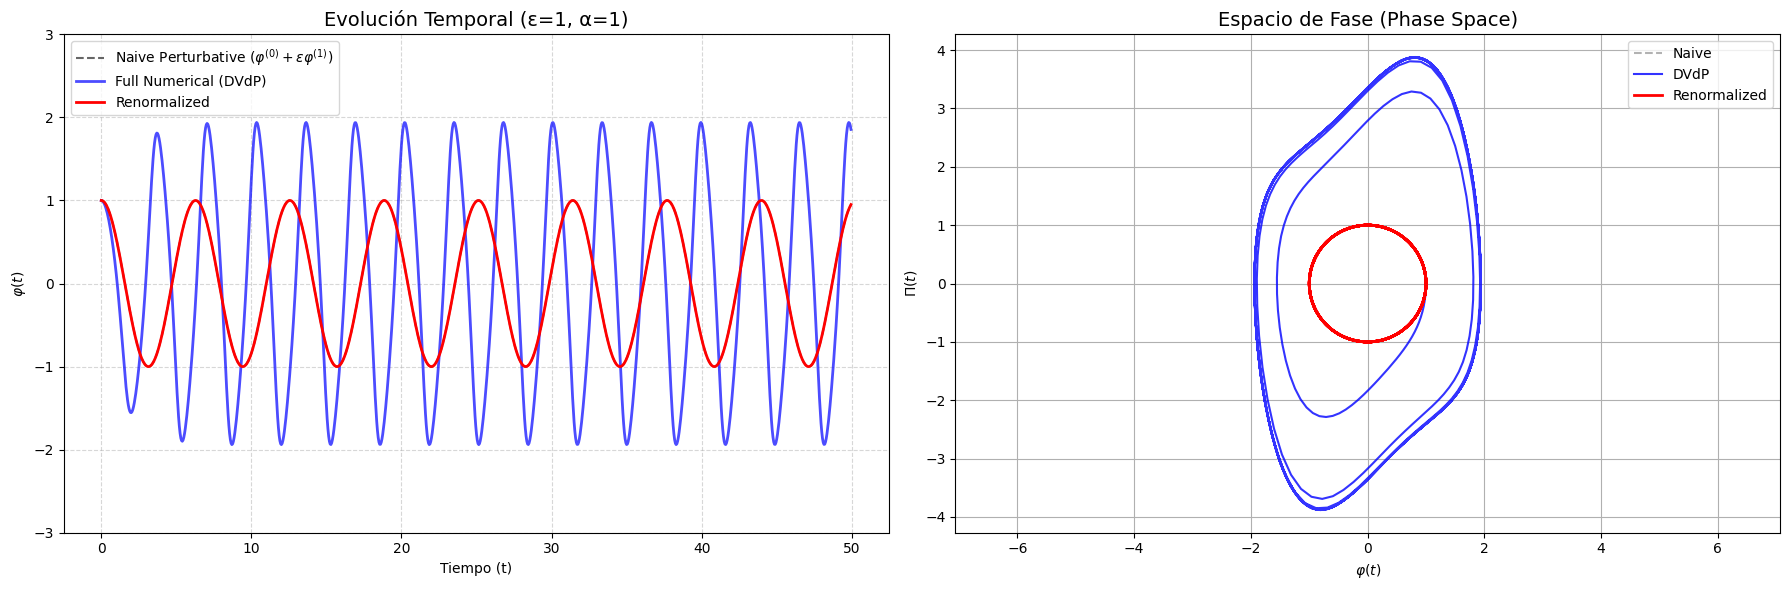

In [ ]:
# @title Algoritmo de Renormalización para Van der Pol

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit

# ---------------------------------------------------------
# 1. CONFIGURACIÓN Y PARÁMETROS (El "Setup")
# ---------------------------------------------------------
omega = 1.0       # Frecuencia angular natural
epsilon = 1     # Parámetro de deformación (pequeño para que funque la teoría)
alpha=1
A0_init = 1.0     # Amplitud inicial
t_start = 0.0
t_end = 50.0     # Tiempo de simulación (largo para ver el ciclo límite)
dt = 0.05
t_eval = np.arange(t_start, t_end, dt)

# ---------------------------------------------------------
# 2. DEFINICIÓN DE SISTEMAS
# ---------------------------------------------------------

# A) Solución "Full" (La exacta)

def full_system(t, y):
    #VANDERPOL
    # phi, Pi = y
    # # Ecuación: dPi/dt = -w^2 phi + eps*(1 - phi^2)*Pi
    # dphi = Pi
    # dPi = -omega**2 * phi + epsilon * (1 - phi**2) * Pi
    # return [dphi, dPi]
    #
    #DUFFING
    #phi, Pi = y
    #dphi = Pi
    #dPi = -omega**2 * phi - epsilon*phi**3

    #DVdP
    phi, Pi = y
    dphi = Pi
    dPi = -omega**2 * phi - epsilon*phi**3+ alpha * (1 - phi**2) * Pi
    return [dphi, dPi]

# B) Solución de Fondo (Background) - Ec. 18 del paper
def phi_0(t, A):
    return A * np.cos(omega * t)

def Pi_0(t, A):
    return -omega * A * np.sin(omega * t)

# C) Sistema Perturbativo (Primer Orden) - Ec. 19 del paper
# Ojo: Aquí calculamos phi_1 (la corrección) asumiendo A constante temporalmente para este paso
def perturbative_system(t, y, A_fixed):
    phi1, Pi1 = y

    p0 = phi_0(t, A_fixed)

    dphi1 = Pi1
    #dPi1 = -omega**2 * phi1 - epsilon* p0**3
    dPi1 = -omega**2 *phi1 - epsilon * phi1**3 +alpha * (1 - phi1**2) * Pi1

    return [dphi1, dPi1]

# ---------------------------------------------------------
# 3. EL NÚCLEO DE LA RENORMALIZACIÓN
# ---------------------------------------------------------

# Creamos una grilla de Amplitudes para caracterizar cómo crece el error en cada nivel
A_grid = np.linspace(0.1, 4.0, 20)
beta_vals = []

# Para cada amplitud A, resolvemos la perturbación y proyectamos el error
for A_val in A_grid:
    # Resolvemos la EDO perturbativa por un periodo corto (suficiente para captar la tendencia secular)
    # No necesitamos integrar hasta t=100, solo ver la "velocidad" de divergencia inicial.
    T_period = 2 * np.pi / omega
    t_short = np.linspace(0, 4*T_period, 100) # 4 periodos

    sol_pert = solve_ivp(perturbative_system, [0, 4*T_period], [0, 0],
                         args=(A_val,), t_eval=t_short, method='RK45')

    phi1_num = sol_pert.y[0]

    # --- PROYECCIÓN (Cálculo de Beta) ---
    # Teoría: phi_total ~= phi0(A) + eps * phi1
    # Renorm: phi_renorm ~= phi0(A(t))
    # La diferencia secular es phi1 ~ t * (d_phi0/dA) * Beta
    # Entonces Beta es la pendiente que mejor ajusta phi1 vs t * d_phi0/dA

    # Derivada del background respecto a A: cos(wt)
    d_phi0_dA = np.cos(omega * t_short)

    # El término secular crece como t. Queremos encontrar Beta tal que:
    # phi1(t) ~= Beta * t * d_phi0_dA
    # Usamos mínimos cuadrados para hallar Beta para este A específico.

    predictor = t_short * d_phi0_dA  # El "x" de la regresión
    response = phi1_num              # El "y" de la regresión

    # Regresión lineal simple pasando por el origen (y = m*x)
    # beta = sum(x*y) / sum(x^2)
    beta = np.sum(predictor * response) / np.sum(predictor**2)
    beta_vals.append(beta)

# Creamos una función interpolada para Beta(A)
# Esto es la Ec. 22 del paper pero numérica: dA/dt = eps * Beta(A)
beta_function = interp1d(A_grid, beta_vals, kind='cubic', fill_value="extrapolate")

# ---------------------------------------------------------
# 4. RESOLVIENDO LOS TRES MÉTODOS
# ---------------------------------------------------------

# --- A. Full Solution ---
sol_full = solve_ivp(full_system, [t_start, t_end], [A0_init, 0], t_eval=t_eval)
y_full = sol_full.y[0]
pi_full = sol_full.y[1]

# --- B. Naive Perturbative Solution ---
# phi_naive = phi0 + eps * phi1 (con A fijo inicial)
sol_naive_pert = solve_ivp(perturbative_system, [t_start, t_end], [0, 0],
                           args=(A0_init,), t_eval=t_eval)
y_naive = phi_0(t_eval, A0_init) + epsilon * sol_naive_pert.y[0]
pi_naive = Pi_0(t_eval, A0_init) + epsilon * sol_naive_pert.y[1]

# --- C. Renormalized Solution ---
# Resolvemos la ecuación de flujo: dA_R/dt = eps * beta(A_R)
def amplitude_flow(t, A):
    return epsilon * beta_function(A)

sol_renorm_amp = solve_ivp(amplitude_flow, [t_start, t_end], [A0_init], t_eval=t_eval)
t_RG = sol_renorm_amp.t
A_R_t = sol_renorm_amp.y[0]

y_renorm = A_R_t * np.cos(omega * t_RG)
pi_renorm = -omega * A_R_t * np.sin(omega * t_RG)
#pi_renorm = -omega * A_R_t * np.sin(omega * t_eval) # Aproximación de momento

# ---------------------------------------------------------
# 5. GRAFICANDO RESULTADOS
# ---------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 6))

# Gráfica 1: Serie de Tiempo
ax1.set_title(f"Evolución Temporal (ε={epsilon}, α={alpha})", fontsize=14)
ax1.plot(t_eval, y_naive, 'k--', alpha=0.6, label=r'Naive Perturbative ($\varphi^{(0)} + \epsilon\varphi^{(1)}$)')
ax1.plot(t_eval, y_full, 'b-', linewidth=2, alpha=0.7, label='Full Numerical (DVdP)')
ax1.plot(t_RG, y_renorm, 'r-', linewidth=2, label='Renormalized')
ax1.set_xlabel('Tiempo (t)')
ax1.set_ylabel(r'$\varphi(t)$')
ax1.legend(loc='upper left')
ax1.grid(True, which='both', linestyle='--', alpha=0.5)
ax1.set_ylim(-3, 3)

# Gráfica 2: Espacio de Fase
ax2.set_title("Espacio de Fase (Phase Space)", fontsize=14)
ax2.plot(y_naive, pi_naive, 'k--', alpha=0.3, label='Naive')
ax2.plot(y_full, pi_full, 'b-', alpha=0.8, label='DVdP')
ax2.plot(y_renorm, pi_renorm, 'r-', linewidth=2, label='Renormalized')
ax2.set_xlabel(r'$\varphi(t)$')
ax2.set_ylabel(r'$\Pi(t)$')
ax2.legend()
ax2.grid(True)
ax2.axis('equal')

plt.tight_layout()
plt.show()

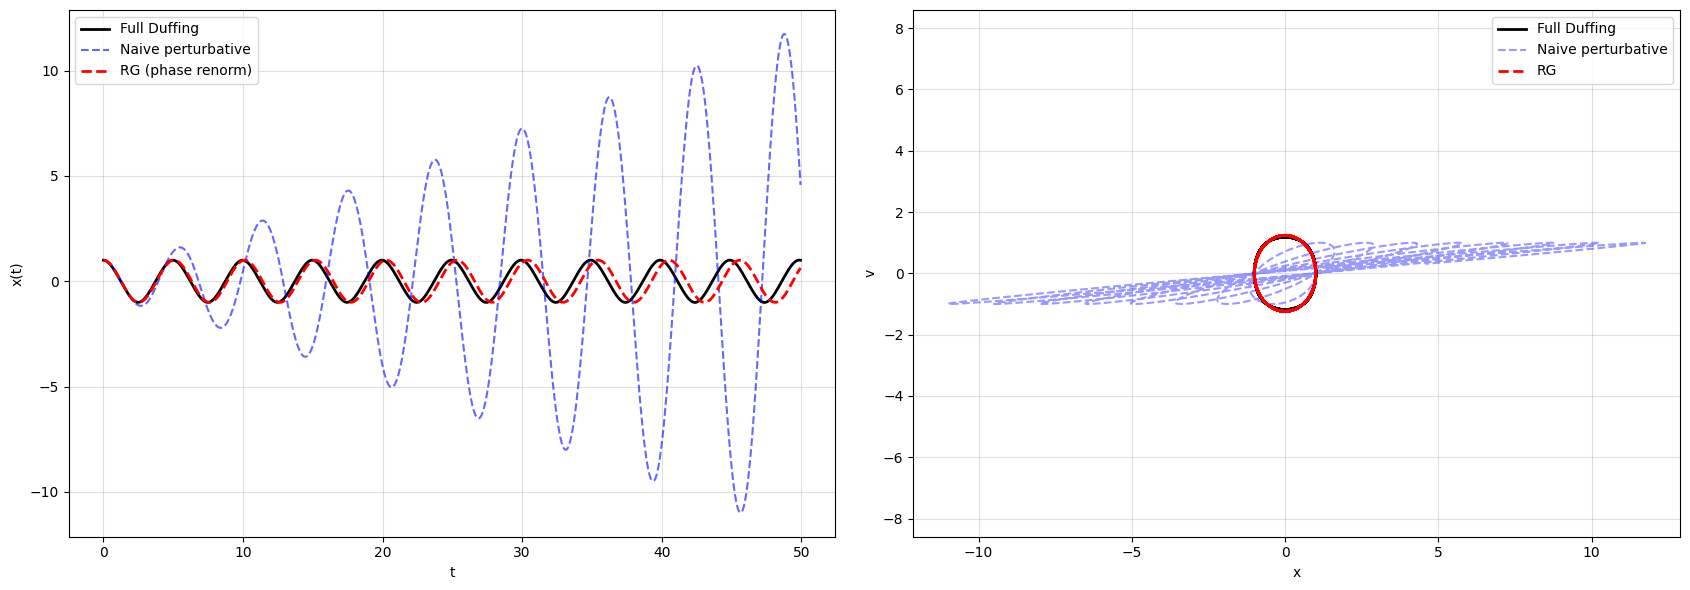

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

# ------------------------------------------------
# 1. PARAMETERS
# ------------------------------------------------
omega = 1.0
epsilon = 0.8
alpha = 1.0

A0 = 1.0
theta0 = 0.0

t0, t1 = 0.0, 50.0
dt = 0.05
t_eval = np.arange(t0, t1, dt)

# ------------------------------------------------
# 2. FULL DUFFING SYSTEM
# ------------------------------------------------
def duffing_full(t, y):
    x, v = y
    dx = v
    dv = -omega**2 * x - epsilon* x**3
    return [dx, dv]

# ------------------------------------------------
# 3. BACKGROUND SOLUTION
# ------------------------------------------------
def phi0(t, A):
    return A * np.cos(omega * t)

def dphi0_dtheta(t, A):
    return -A * np.sin(omega * t)

# ------------------------------------------------
# 4. FIRST-ORDER PERTURBATION SYSTEM
# ------------------------------------------------
def perturbation_system(t, y, A):
    phi1, pi1 = y
    p0 = phi0(t, A)

    dphi1 = pi1
    dpi1 = -omega**2 * phi1 - epsilon * p0**3

    return [dphi1, dpi1]

# ------------------------------------------------
# 5. EXTRACT PHASE RG FUNCTION Omega(A)
# ------------------------------------------------
A_grid = np.linspace(0.3, 3.0, 20)
Omega_vals = []

T = 2 * np.pi / omega

for A in A_grid:
    t_short = np.linspace(0, 6*T, 600)

    sol = solve_ivp(
        perturbation_system,
        [0, 6*T],
        [0.0, 0.0],
        args=(A,),
        t_eval=t_short
    )

    phi1 = sol.y[0]

    predictor = t_short * dphi0_dtheta(t_short, A)
    Omega = np.sum(predictor * phi1) / np.sum(predictor**2)

    Omega_vals.append(Omega)

Omega_func = interp1d(
    A_grid, Omega_vals,
    kind="cubic",
    fill_value="extrapolate"
)

# ------------------------------------------------
# 6. RG FLOW (PHASE ONLY)
# ------------------------------------------------
def phase_flow(t, theta, A):
    return epsilon * Omega_func(A)

sol_theta = solve_ivp(
    phase_flow,
    [t0, t1],
    [theta0],
    args=(A0,),
    t_eval=t_eval
)

theta_t = sol_theta.y[0]

# ------------------------------------------------
# 7. RENORMALIZED SOLUTION
# ------------------------------------------------
x_RG = A0 * np.cos(omega * t_eval + theta_t)
v_RG = -A0 * (omega + epsilon * Omega_func(A0)) \
       * np.sin(omega * t_eval + theta_t)

# ------------------------------------------------
# 8. NAIVE PERTURBATIVE SOLUTION
# ------------------------------------------------
sol_naive = solve_ivp(
    perturbation_system,
    [t0, t1],
    [0.0, 0.0],
    args=(A0,),
    t_eval=t_eval
)

phi1_naive = sol_naive.y[0]

x_naive = phi0(t_eval, A0) + epsilon * phi1_naive
v_naive = -omega * A0 * np.sin(omega * t_eval)

# ------------------------------------------------
# 9. FULL NUMERICAL SOLUTION
# ------------------------------------------------
sol_full = solve_ivp(
    duffing_full,
    [t0, t1],
    [A0, 0.0],
    t_eval=t_eval
)

x_full = sol_full.y[0]
v_full = sol_full.y[1]

# ------------------------------------------------
# 10. PLOTS
# ------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6))

# Time series
ax1.plot(t_eval, x_full, 'k', lw=2, label="Full Duffing")
ax1.plot(t_eval, x_naive, 'b--', alpha=0.6, label="Naive perturbative")
ax1.plot(t_eval, x_RG, 'r--', lw=2, label="RG (phase renorm)")
ax1.set_xlabel("t")
ax1.set_ylabel("x(t)")
ax1.legend()
ax1.grid(alpha=0.4)

# Phase space
ax2.plot(x_full, v_full, 'k', lw=2, label="Full Duffing")
ax2.plot(x_naive, v_naive, 'b--', alpha=0.4, label="Naive perturbative")
ax2.plot(x_RG, v_RG, 'r--', lw=2, label="RG")
ax2.set_xlabel("x")
ax2.set_ylabel("v")
ax2.axis("equal")
ax2.legend()
ax2.grid(alpha=0.4)

plt.tight_layout()
plt.show()
